Loading dataset from: IMDB Dataset.csv
Could not load CSV due to error: No columns to parse from file. Falling back to tf.keras.datasets.imdb...
Epoch 1/3


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


110/110 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.5409 - loss: 0.6904 - val_accuracy: 0.6093 - val_loss: 0.6755
Epoch 2/3
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7097 - loss: 0.5820 - val_accuracy: 0.7160 - val_loss: 0.5738
Epoch 3/3
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8346 - loss: 0.4113 - val_accuracy: 0.7587 - val_loss: 0.5355
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Accuracy: 0.7426666666666667
Precision: 0.8118811881188119
Recall: 0.643979057591623
F1 Score: 0.7182481751824817


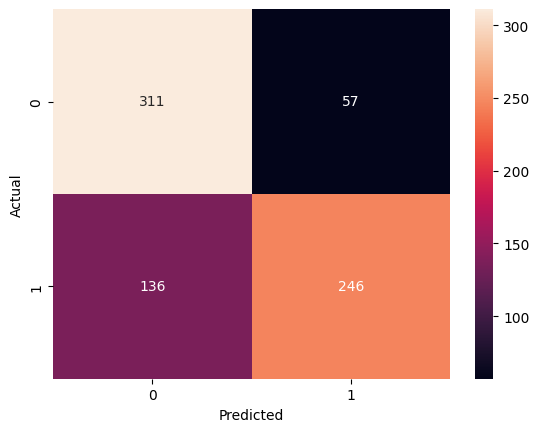

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Review 1 : Positive
Review 2 : Negative
Review 3 : Positive
Review 4 : Negative
Review 5 : Negative


In [18]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
from sklearn.model_selection import train_test_split
from sklearn.metrics import *
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

dataset_path = 'IMDB Dataset.csv'
if not os.path.exists(dataset_path):
    possible_paths = [
        '/content/IMDB Dataset.csv',
        'nlp-basics-imdb-movie-review-sentiment/IMDB Dataset.csv'
    ]
    for p in possible_paths:
        if os.path.exists(p):
            dataset_path = p
            break

loaded_csv = False
try:
    print(f"Loading dataset from: {dataset_path}")
    df = pd.read_csv(dataset_path)
    if df.empty:
        raise ValueError("CSV is empty")
    df['sentiment'] = df['sentiment'].map({'positive': 1, 'negative': 0})

    def clean_text(text):
        text = text.lower()
        text = re.sub(r'<br\s*/?>', ' ', text)
        text = re.sub(r'[^a-z ]', '', text)
        return text

    cleaned = [clean_text(r) for r in df['review']]
    labels = df['sentiment'].values

    max_words = 5000
    max_len = 100

    tok = Tokenizer(num_words=max_words, oov_token='<OOV>')
    tok.fit_on_texts(cleaned)
    x = pad_sequences(tok.texts_to_sequences(cleaned), maxlen=max_len, padding='post', truncating='post')
    x, y = x[:5000], labels[:5000]
    loaded_csv = True
except Exception as e:
    print(f"Could not load CSV due to error: {e}. Falling back to tf.keras.datasets.imdb...")
    max_words = 5000
    max_len = 100
    (x_raw, y_raw), _ = tf.keras.datasets.imdb.load_data(num_words=max_words)
    x = pad_sequences(x_raw[:5000], maxlen=max_len, padding='post', truncating='post')
    y = y_raw[:5000]
    word_index = tf.keras.datasets.imdb.get_word_index()
    word_index = {k: (v + 3) for k, v in word_index.items()}
    word_index["<PAD>"] = 0
    word_index["<START>"] = 1
    word_index["<UNK>"] = 2
    word_index["<UNUSED>"] = 3

    def encode_new_text(texts):
        sequences = []
        for text in texts:
            clean = re.sub(r'[^a-zA-Z\s]', '', text).lower().split()
            seq = [word_index.get(word, 2) for word in clean] # fallback to <UNK>
            sequences.append([i if i < max_words else 2 for i in seq])
        return pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

X_train, X_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.30, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(max_words, 32, input_length=max_len),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="adam",
              loss="binary_crossentropy", metrics=["accuracy"])

model.fit(X_train, y_train, epochs=3, batch_size=32,
          validation_data=(X_val, y_val))

pred = (model.predict(X_test).ravel() > 0.5).astype(int)
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, zero_division=0))
print("Recall:", recall_score(y_test, pred, zero_division=0))
print("F1 Score:", f1_score(y_test, pred, zero_division=0))

sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
if loaded_csv:
    new_reviews = pad_sequences(tok.texts_to_sequences(raw_test_reviews), maxlen=max_len, padding='post', truncating='post')
else:
    new_reviews = encode_new_text(raw_test_reviews)

for i, p in enumerate(model.predict(new_reviews).ravel()):
    print(f"Review {i+1} : {'Positive' if p > 0.5 else 'Negative'}")